<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/ViDr_CXR_VQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ViDr-CXR-VQA Dataset Analysis

This notebook analyzes the ViDr-CXR-VQA dataset for the doctoral research project (Paper 2).
It follows a structure similar to VQA-RAD and SLAKE, using only allowed variables.

## 1. Import Libraries

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Visualization configuration
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)



## 2. Data Loading

In [2]:
from google.colab import files
import json
import pandas as pd

# Select and load the file from the computer
uploaded_files = files.upload()

# Get the uploaded file name
file_name = next(iter(uploaded_files))

# Read the JSON file
json_data = json.loads(uploaded_files[file_name].decode('utf-8'))

# Convert it to a DataFrame
df = pd.DataFrame(json_data)

Saving ViDr-CXR-VQA.json to ViDr-CXR-VQA.json


In [4]:
df.head(10)

,image_id,num_questions,vqa
0,9a5094b2563a1ef3ff50dc5c7ff71345,3,"[{'question': 'Where is the Cardiomegaly?', 'a..."
1,051132a778e61a86eb147c7c6f564dfe,3,"[{'question': 'Is there Cardiomegaly?', 'answe..."
2,1c32170b4af4ce1a3030eb8167753b06,3,"[{'question': 'How many findings are there?', ..."
3,0c7a38f293d5f5e4846aa4ca6db4daf1,4,"[{'question': 'What abnormality is visible?', ..."
4,47ed17dcb2cbeec15182ed335a8b5a9e,5,"[{'question': 'Is there Lung Opacity?', 'answe..."
5,afb6230703512afc370f236e8fe98806,5,"[{'question': 'How many findings are there?', ..."
6,7c1add6833d5f0102b0d3619a1682a64,4,"[{'question': 'Is there Lung Opacity?', 'answe..."
7,18a61a07e6f5f13ebfee57fa36cd8b6f,3,"[{'question': 'What abnormality is visible?', ..."
8,321c111713c3ee5385db0effb54ff568,5,[{'question': 'Where is the Pulmonary fibrosis...
9,80caa435b6ab5edaff4a0a758ffaec6e,4,"[{'question': 'How many findings are there?', ..."


### 2.1. Allowed Variables

In [5]:
variables = [
    'image_id',
    'num_questions',
    'vqa'
 ]

vqa_variables = [
    'question',
    'answer',
    'reason',
    'type',
    'difficulty',
    'gt_finding'
 ]

print("Allowed variables in ViDr-CXR-VQA:")
for variable in variables:
    print(f"  - {variable}")

print("\nAllowed variables within vqa:")
for variable in vqa_variables:
    print(f"  - {variable}")

Allowed variables in ViDr-CXR-VQA:
  - image_id
  - num_questions
  - vqa

Allowed variables within vqa:
  - question
  - answer
  - reason
  - type
  - difficulty
  - gt_finding


## 3. Data Preparation

In [6]:
df_base = df

def count_words(text: str) -> int:
    """Count words in a text using simple space separation.

    Args:
        text: The text to analyze.

    Returns:
        The number of words.
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    return len(text.split())

def clean_answer(text: str) -> str:
    """
    Remove tags enclosed in <> from answers.

    Args:
        text: The original text.

    Returns:
        The text without tags enclosed in <>.
    """
    if not isinstance(text, str):
        return ''
    text = pd.Series([text]).str.replace(r"<[^>]*>", "", regex=True).iloc[0]
    text = pd.Series([text]).str.replace(r"\s+", " ", regex=True).iloc[0]
    return text.strip()

df_vqa = df_base.explode('vqa').reset_index(drop=True)
vqa_norm = pd.json_normalize(df_vqa['vqa'])
df_vqa = pd.concat([df_vqa[['image_id', 'num_questions']], vqa_norm], axis=1)

df_vqa['question'] = df_vqa['question'].fillna('')
df_vqa['answer'] = df_vqa['answer'].fillna('')
df_vqa['reason'] = df_vqa['reason'].fillna('')
df_vqa['type'] = df_vqa['type'].fillna('Unknown')
df_vqa['difficulty'] = df_vqa['difficulty'].fillna('Unknown')
df_vqa['gt_finding'] = df_vqa['gt_finding'].fillna('Unknown')

df_vqa['answer'] = df_vqa['answer'].apply(clean_answer)

df_vqa['question_length'] = df_vqa['question'].str.len()
df_vqa['answer_length'] = df_vqa['answer'].str.len()
df_vqa['reason_length'] = df_vqa['reason'].str.len()

df_vqa['question_words'] = df_vqa['question'].apply(count_words)
df_vqa['answer_words'] = df_vqa['answer'].apply(count_words)
df_vqa['reason_words'] = df_vqa['reason'].apply(count_words)

print("Data prepared successfully")
print(f"Total QA pairs: {len(df_vqa)}")
print("Available columns:")
print(df_vqa.columns.tolist())

Data prepared successfully
Total QA pairs: 17597
Available columns:
['image_id', 'num_questions', 'question', 'answer', 'reason', 'type', 'difficulty', 'gt_finding', 'gt_location', 'question_length', 'answer_length', 'reason_length', 'question_words', 'answer_words', 'reason_words']


## 4. Exploratory Data Analysis

**Note on the unit of analysis**

ViDr-CXR-VQA contains multiple questions per image. Therefore, section 4.1 summarizes data at the image level with `num_questions`, while sections 4.2 through 4.7 work at the question-answer pair level after expanding `vqa`.

### 4.1. Distribution of Questions per Image

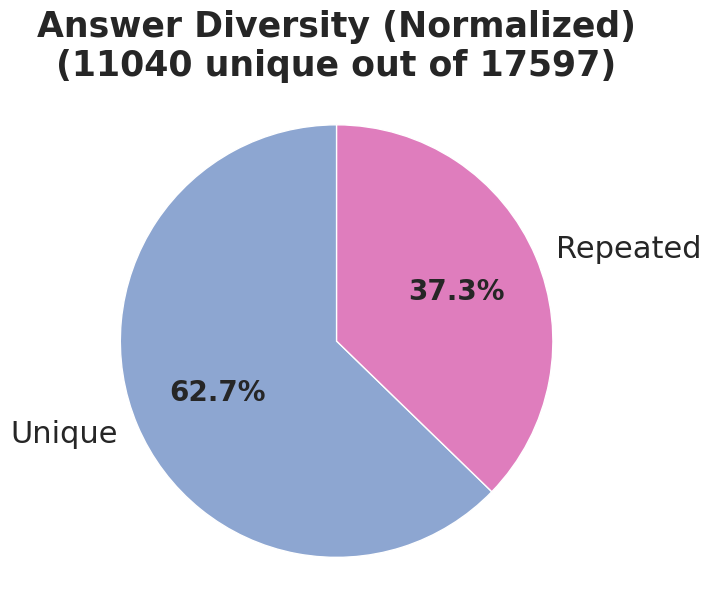

In [7]:
# ============================================================
# FIGURE 1: NORMALIZED ANSWER DIVERSITY
# ViDr-CXR-VQA
# ============================================================

# Normalize the answers
normalized_answers = (
    df_vqa['answer']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty answers
normalized_answers = normalized_answers[
    normalized_answers != ''
]

# Calculate counts
total_answers = len(normalized_answers)
unique_answers = normalized_answers.nunique()
repeated_answers = total_answers - unique_answers

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, percentages = ax.pie(
    [unique_answers, repeated_answers],
    labels=['Unique', 'Repeated'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8DA6D1', '#DF7DBD'],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 22
    }
)

# Format percentages only
for percentage in percentages:
    percentage.set_fontsize(20)
    percentage.set_fontweight('bold')

ax.set_title(
    f'Answer Diversity (Normalized)\n'
    f'({unique_answers} unique out of {total_answers})',
    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

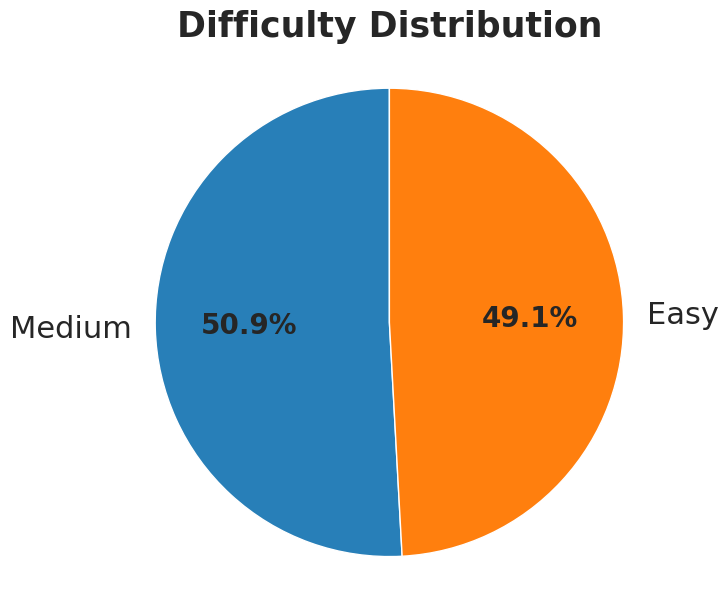

In [8]:
# ============================================================
# FIGURE 2: DIFFICULTY DISTRIBUTION
# ViDr-CXR-VQA
# ============================================================

# Normalize difficulty categories
difficulty = (
    df_vqa['difficulty']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.capitalize()
)

# Remove empty or unknown values
difficulty = difficulty[
    ~difficulty.isin(['', 'Unknown', 'Nan', 'None'])
]

# Count the categories
difficulty_counts = difficulty.value_counts()

# Preserve the order shown in the original figure
order = ['Medium', 'Easy']

difficulty_counts = difficulty_counts.reindex(
    order,
    fill_value=0
)

# Remove nonexistent categories
difficulty_counts = difficulty_counts[
    difficulty_counts > 0
]

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, percentages = ax.pie(
    difficulty_counts.values,
    labels=difficulty_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#287FB8', '#FF7F0E'],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 22
    }
)

# Format percentages only
for percentage in percentages:
    percentage.set_fontsize(20)
    percentage.set_fontweight('bold')

ax.set_title(
    'Difficulty Distribution',
    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

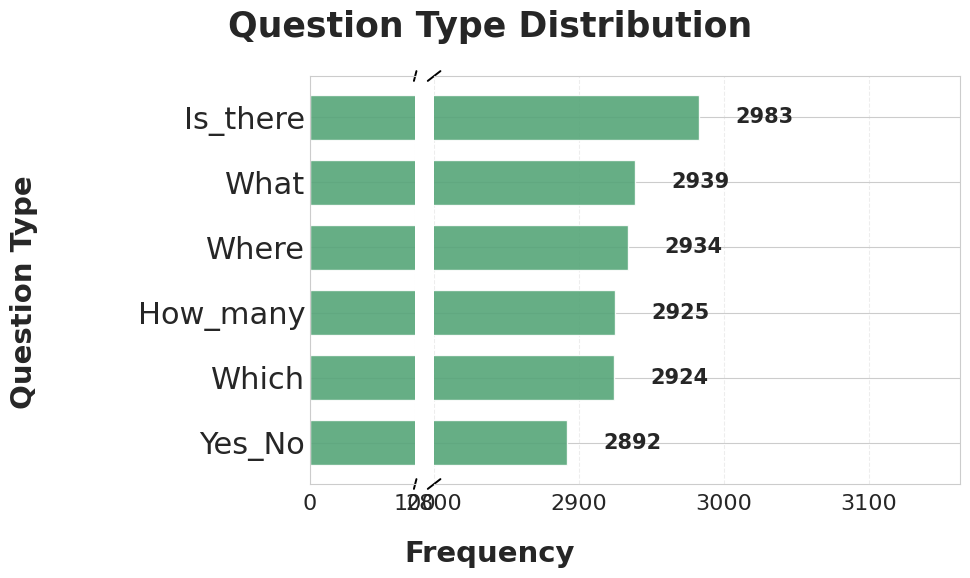

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Normalize the question types
question_types = (
    df_vqa['type']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
)

# Remove empty or unknown values
question_types = question_types[
    ~question_types.str.lower().isin(
        ['', 'unknown', 'nan', 'none']
    )
]

# Calculate frequencies
type_counts = (
    question_types
    .value_counts()
    .sort_values(ascending=False)
)

# Original positions
positions = np.arange(len(type_counts)) * 0.60

# Two axes to represent the break
fig, (left_ax, right_ax) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(10, 6),
    gridspec_kw={
        'width_ratios': [1, 5],
        'wspace': 0.06
    }
)

# Draw the same bars on both axes
for ax in (left_ax, right_ax):
    ax.barh(
        positions,
        type_counts.values,
        color='#55A578',
        height=0.42,
        alpha=0.9
    )

    ax.set_yticks(positions)
    ax.tick_params(axis='x', labelsize=16)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)

# Preserve the order of the original chart
left_ax.invert_yaxis()

# Labels with the original size
left_ax.set_yticklabels(
    type_counts.index,
    fontsize=22
)

left_ax.tick_params(axis='y', length=0)
right_ax.tick_params(axis='y', left=False, labelleft=False)

# Visible ranges before and after the break
left_ax.set_xlim(0, 100)
right_ax.set_xlim(2800, max(type_counts.values) + 180)

# Hide the borders at the break
left_ax.spines['right'].set_visible(False)
right_ax.spines['left'].set_visible(False)

# Draw the diagonal break marks
d = 0.012
break_style = dict(
    color='black',
    clip_on=False,
    linewidth=1.4
)

left_ax.plot(
    (1 - d, 1 + d), (-d, +d),
    transform=left_ax.transAxes,
    **break_style
)
left_ax.plot(
    (1 - d, 1 + d), (1 - d, 1 + d),
    transform=left_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (-d, +d),
    transform=right_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (1 - d, 1 + d),
    transform=right_ax.transAxes,
    **break_style
)

# Values at the end of each bar: original size
for position, value in zip(positions, type_counts.values):
    right_ax.text(
        value + 25,
        position,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

# Title and axis names with the original sizes
fig.suptitle(
    'Question Type Distribution',
    fontsize=25,
    fontweight='bold',
    y=0.97
)

fig.supxlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    y=0.04
)

fig.supylabel(
    'Question Type',
    fontsize=21,
    fontweight='bold',
    x=0.02
)

# Reserve space for the large labels
fig.subplots_adjust(
    left=0.32,
    right=0.97,
    top=0.86,
    bottom=0.18
)

plt.show()

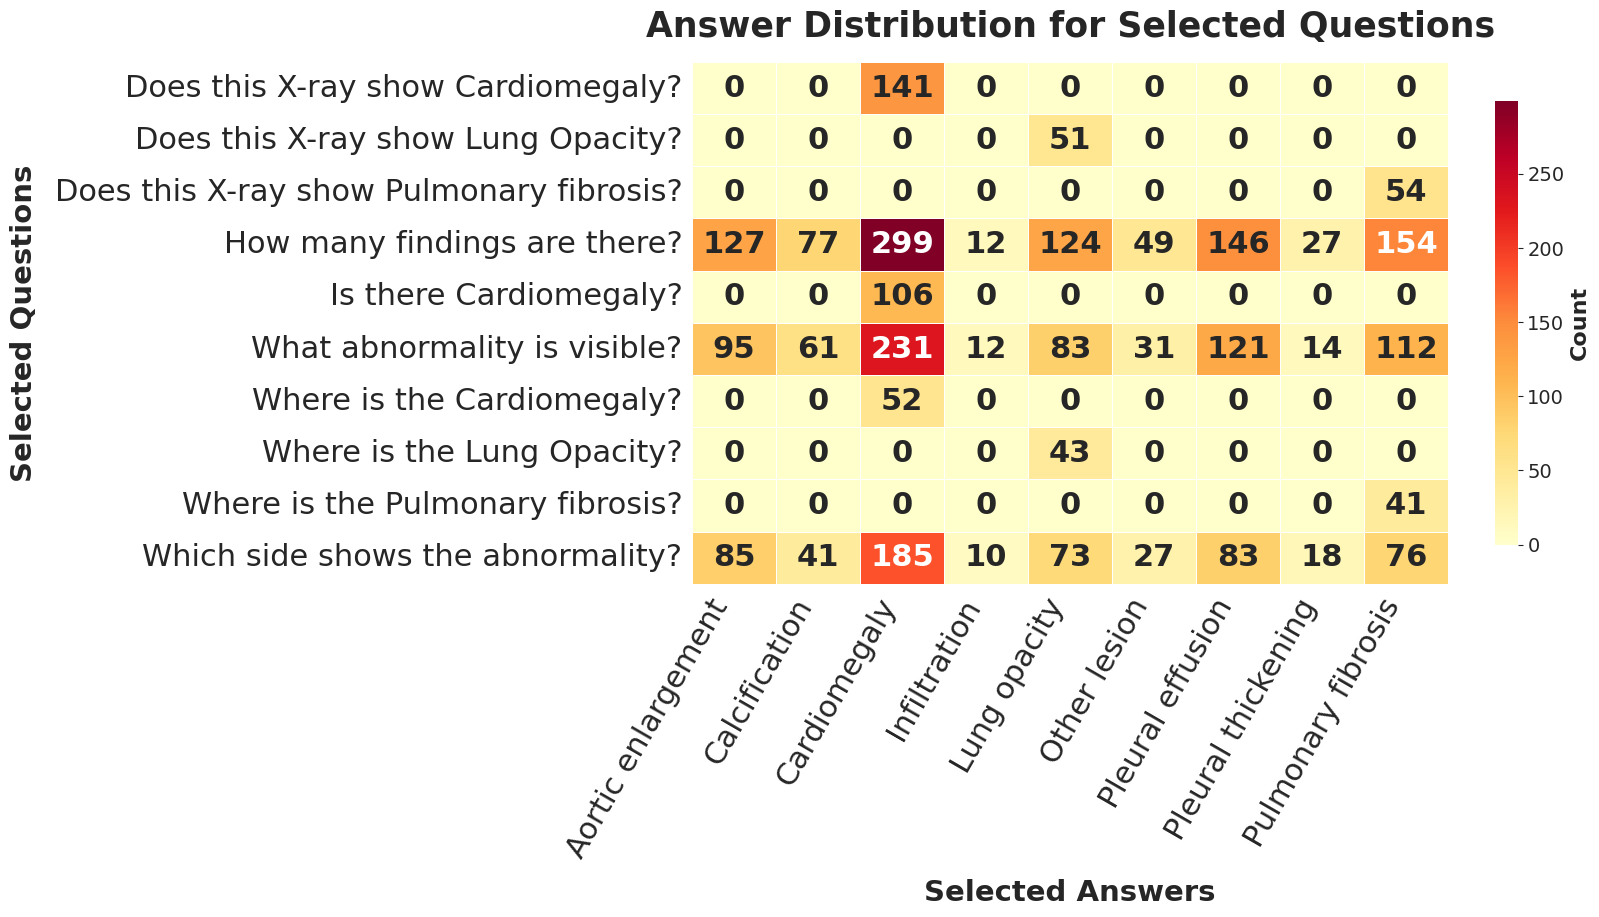

In [10]:
# ============================================================
# FIGURE 4: ANSWER DISTRIBUTION FOR SELECTED QUESTIONS
# ViDr-CXR-VQA
# ============================================================

# Normalize questions and answers
df_heatmap = pd.DataFrame({
    'question': (
        df_vqa['question']
        .fillna('')
        .astype(str)
        .str.lower()
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    ),
    'answer': (
        df_vqa['answer']
        .fillna('')
        .astype(str)
        .str.lower()
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )
})

# Remove empty rows
df_heatmap = df_heatmap[
    (df_heatmap['question'] != '') &
    (df_heatmap['answer'] != '')
]

# Selected questions
selected_questions = [
    'does this x-ray show cardiomegaly?',
    'does this x-ray show lung opacity?',
    'does this x-ray show pulmonary fibrosis?',
    'how many findings are there?',
    'is there cardiomegaly?',
    'what abnormality is visible?',
    'where is the cardiomegaly?',
    'where is the lung opacity?',
    'where is the pulmonary fibrosis?',
    'which side shows the abnormality?'
]

# Specific answers shown in the figure
selected_answers = [
    'yes, aortic enlargement',
    'yes, calcification',
    'yes, cardiomegaly',
    'yes, infiltration',
    'yes, lung opacity',
    'yes, other lesion',
    'yes, pleural effusion',
    'yes, pleural thickening',
    'yes, pulmonary fibrosis'
]

# Create frequency table
heatmap_table = pd.crosstab(
    df_heatmap['question'],
    df_heatmap['answer']
)

# Select and order rows and columns
heatmap_table = heatmap_table.reindex(
    index=selected_questions,
    columns=selected_answers,
    fill_value=0
)

# Short answer labels
answer_labels = [
    'Aortic enlargement',
    'Calcification',
    'Cardiomegaly',
    'Infiltration',
    'Lung opacity',
    'Other lesion',
    'Pleural effusion',
    'Pleural thickening',
    'Pulmonary fibrosis'
]

# Question labels
question_labels = [
    'Does this X-ray show Cardiomegaly?',
    'Does this X-ray show Lung Opacity?',
    'Does this X-ray show Pulmonary fibrosis?',
    'How many findings are there?',
    'Is there Cardiomegaly?',
    'What abnormality is visible?',
    'Where is the Cardiomegaly?',
    'Where is the Lung Opacity?',
    'Where is the Pulmonary fibrosis?',
    'Which side shows the abnormality?'
]

# Create figure
fig, ax = plt.subplots(figsize=(15, 9))

sns.heatmap(
    heatmap_table,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.6,
    linecolor='white',
    cbar_kws={
        'label': 'Count',
        'shrink': 0.85
    },
    annot_kws={
        'fontsize': 22,
        'fontweight': 'bold'
    },
    ax=ax
)

ax.set_title(
    'Answer Distribution for Selected Questions',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Selected Answers',
    fontsize=21,
    fontweight='bold',
    labelpad=12
)

ax.set_ylabel(
    'Selected Questions',
    fontsize=21,
    fontweight='bold',
    labelpad=12
)

ax.set_xticklabels(
    answer_labels,
    rotation=60,
    ha='right',
    fontsize=22
)

ax.set_yticklabels(
    question_labels,
    rotation=0,
    fontsize=22
)

# Color bar
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=14)
colorbar.set_label(
    'Count',
    fontsize=16,
    fontweight='bold'
)

# Adjust the margins manually
plt.subplots_adjust(
    left=0.30,
    right=0.93,
    bottom=0.30,
    top=0.88
)

plt.show()

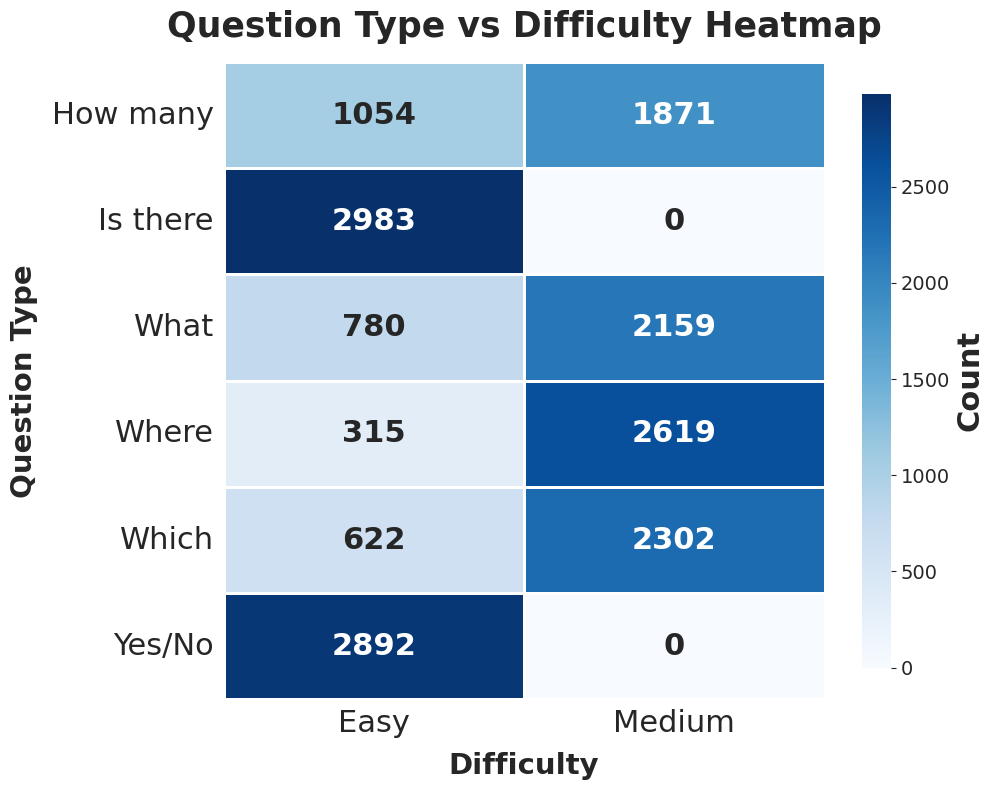

In [11]:
# ============================================================
# FIGURE 5: QUESTION TYPE VS DIFFICULTY HEATMAP
# ViDr-CXR-VQA
# ============================================================

# Create a copy with the required columns
difficulty_df = df_vqa[
    ['type', 'difficulty']
].copy()

# Normalize the question types
difficulty_df['type'] = (
    difficulty_df['type']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
    .str.lower()
)

# Normalize difficulty categories
difficulty_df['difficulty'] = (
    difficulty_df['difficulty']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.capitalize()
)

# Remove empty or unknown values
difficulty_df = difficulty_df[
    ~difficulty_df['type'].isin(
        ['', 'unknown', 'nan', 'none']
    )
    &
    ~difficulty_df['difficulty'].isin(
        ['', 'Unknown', 'Nan', 'None']
    )
]

# Create frequency table
difficulty_table = pd.crosstab(
    difficulty_df['type'],
    difficulty_df['difficulty']
)

# Order used in the original figure
type_order = [
    'how_many',
    'is_there',
    'what',
    'where',
    'which',
    'yes_no'
]

difficulty_order = [
    'Easy',
    'Medium'
]

# Apply the order and fill missing combinations with zero
difficulty_table = difficulty_table.reindex(
    index=type_order,
    columns=difficulty_order,
    fill_value=0
)

# Labels to display
type_labels = [
    'How many',
    'Is there',
    'What',
    'Where',
    'Which',
    'Yes/No'
]

# Create figure
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    difficulty_table,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={
        'label': 'Count',
        'shrink': 0.90
    },
    annot_kws={
        'fontsize': 22,
        'fontweight': 'bold'
    },
    ax=ax
)

ax.set_title(
    'Question Type vs Difficulty Heatmap',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Difficulty',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Question Type',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_xticklabels(
    difficulty_order,
    rotation=0,
    fontsize=22
)

ax.set_yticklabels(
    type_labels,
    rotation=0,
    fontsize=22
)

# Configure the color bar
colorbar = ax.collections[0].colorbar

colorbar.ax.tick_params(
    labelsize=14
)

colorbar.set_label(
    'Count',
    fontsize=22,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

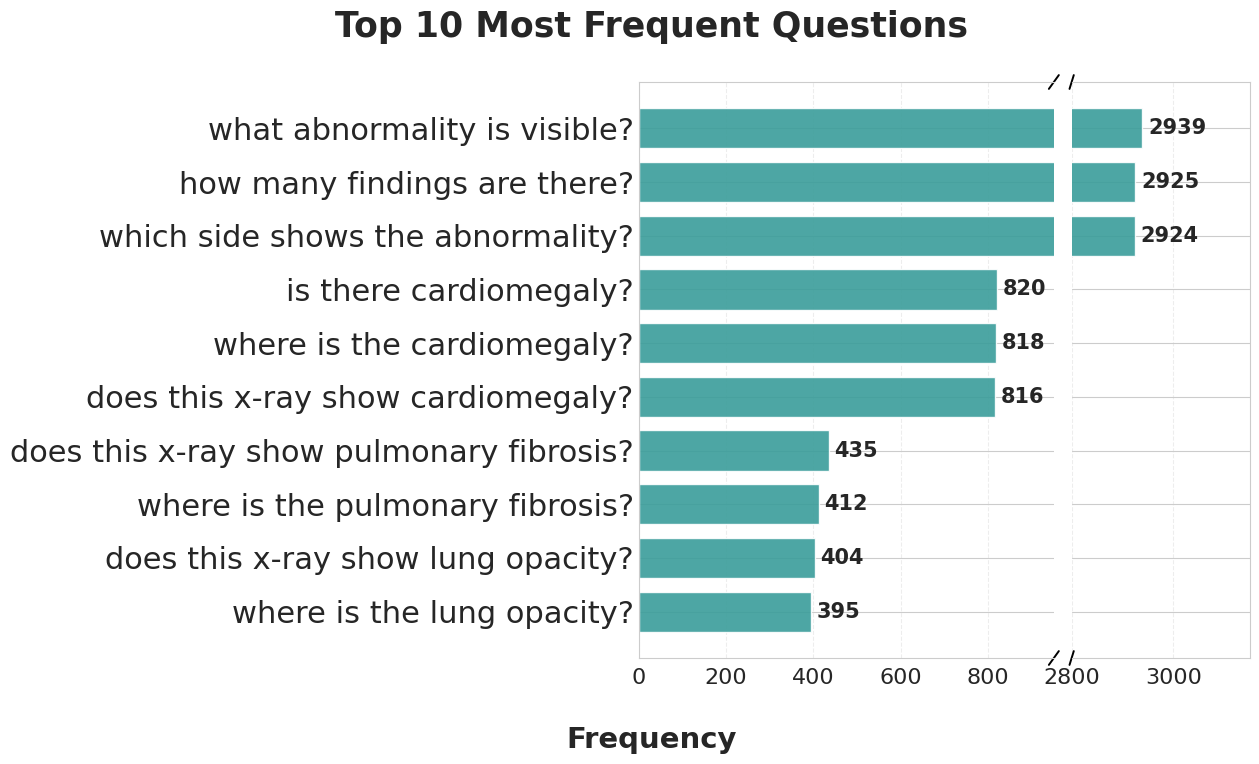

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Normalize the questions
normalized_questions = (
    df_vqa['question']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty questions
normalized_questions = normalized_questions[
    normalized_questions != ''
]

# Get the 10 most frequent questions
top_questions = (
    normalized_questions
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Abbreviate questions that are too long
labels = [
    question if len(question) <= 65
    else question[:62] + '...'
    for question in top_questions.index
]

positions = np.arange(len(top_questions)) * 0.60

# Two axes to create a horizontal break
fig, (left_ax, right_ax) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(13, 8),
    gridspec_kw={
        'width_ratios': [3.5, 1.5],
        'wspace': 0.06
    }
)

for ax in (left_ax, right_ax):
    ax.barh(
        positions,
        top_questions.values,
        color='#3A9D9A',
        height=0.45,
        alpha=0.9
    )
    ax.set_yticks(positions)
    ax.tick_params(axis='x', labelsize=16)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)

# Labels: same size as in the original figure
left_ax.set_yticklabels(labels, fontsize=22)
left_ax.tick_params(axis='y', length=0)
right_ax.tick_params(axis='y', left=False, labelleft=False)

# Ranges on both sides of the break
left_ax.set_xlim(0, 950)
right_ax.set_xlim(2800, 3150)

# Hide the inner borders
left_ax.spines['right'].set_visible(False)
right_ax.spines['left'].set_visible(False)

# Diagonal marks indicating the break
d = 0.012
break_style = dict(color='black', clip_on=False, linewidth=1.4)

left_ax.plot(
    (1-d, 1+d), (-d, +d),
    transform=left_ax.transAxes,
    **break_style
)
left_ax.plot(
    (1-d, 1+d), (1-d, 1+d),
    transform=left_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (-d, +d),
    transform=right_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (1-d, 1+d),
    transform=right_ax.transAxes,
    **break_style
)

# Values at the end of the bars, retaining fontsize=15
for position, value in zip(positions, top_questions.values):
    value_ax = left_ax if value <= 950 else right_ax

    value_ax.text(
        value + 12,
        position,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

fig.suptitle(
    'Top 10 Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    y=0.97
)

fig.supxlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    y=0.04
)

# Space for the questions without reducing the font size
fig.subplots_adjust(
    left=0.49,
    right=0.96,
    top=0.88,
    bottom=0.16
)

plt.show()

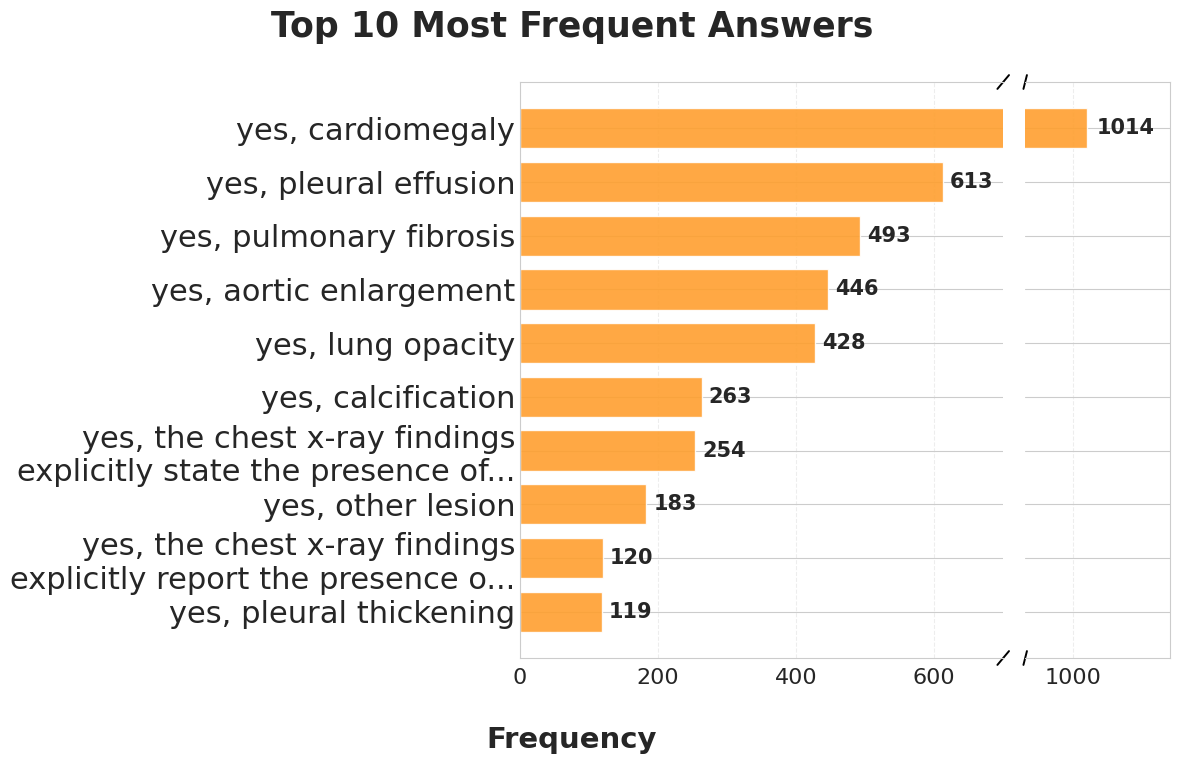

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import textwrap

# Normalize the answers
normalized_answers = (
    df_vqa['answer']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty answers
normalized_answers = normalized_answers[
    normalized_answers != ''
]

# Get the 10 most frequent answers
top_answers = (
    normalized_answers
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Abbreviate and split long answers across two lines
answer_labels = []

for answer in top_answers.index:
    text = (
        answer if len(answer) <= 65
        else answer[:62].rstrip() + '...'
    )

    answer_labels.append(
        textwrap.fill(
            text,
            width=38,
            break_long_words=False,
            break_on_hyphens=False
        )
    )

positions = np.arange(len(top_answers)) * 0.60

# Create two axes to represent the break
fig, (left_ax, right_ax) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(13, 8),
    gridspec_kw={
        'width_ratios': [4, 1.2],
        'wspace': 0.07
    }
)

# Draw the same bars on both axes
for ax in (left_ax, right_ax):
    ax.barh(
        positions,
        top_answers.values,
        color='#FF9F2F',
        height=0.45,
        alpha=0.9
    )
    ax.set_yticks(positions)
    ax.tick_params(axis='x', labelsize=16)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)

# Labels with the original size
left_ax.set_yticklabels(
    answer_labels,
    fontsize=22
)
left_ax.tick_params(axis='y', length=0)
right_ax.tick_params(axis='y', left=False, labelleft=False)

# The axis jumps from 700 to 950
left_ax.set_xlim(0, 700)
right_ax.set_xlim(950, 1100)

left_ax.set_xticks([0, 200, 400, 600])
right_ax.set_xticks([1000])

# Hide the inner borders
left_ax.spines['right'].set_visible(False)
right_ax.spines['left'].set_visible(False)

# Diagonal break marks
d = 0.012
break_style = dict(
    color='black',
    clip_on=False,
    linewidth=1.4
)

left_ax.plot(
    (1-d, 1+d), (-d, +d),
    transform=left_ax.transAxes,
    **break_style
)
left_ax.plot(
    (1-d, 1+d), (1-d, 1+d),
    transform=left_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (-d, +d),
    transform=right_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (1-d, 1+d),
    transform=right_ax.transAxes,
    **break_style
)

# Display each frequency at the end of its bar
for position, value in zip(positions, top_answers.values):
    value_ax = left_ax if value <= 700 else right_ax

    value_ax.text(
        value + 10,
        position,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

fig.suptitle(
    'Top 10 Most Frequent Answers',
    fontsize=25,
    fontweight='bold',
    y=0.97
)

fig.supxlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    y=0.04
)

# Space for long labels
fig.subplots_adjust(
    left=0.46,
    right=0.96,
    top=0.88,
    bottom=0.16
)

plt.show()

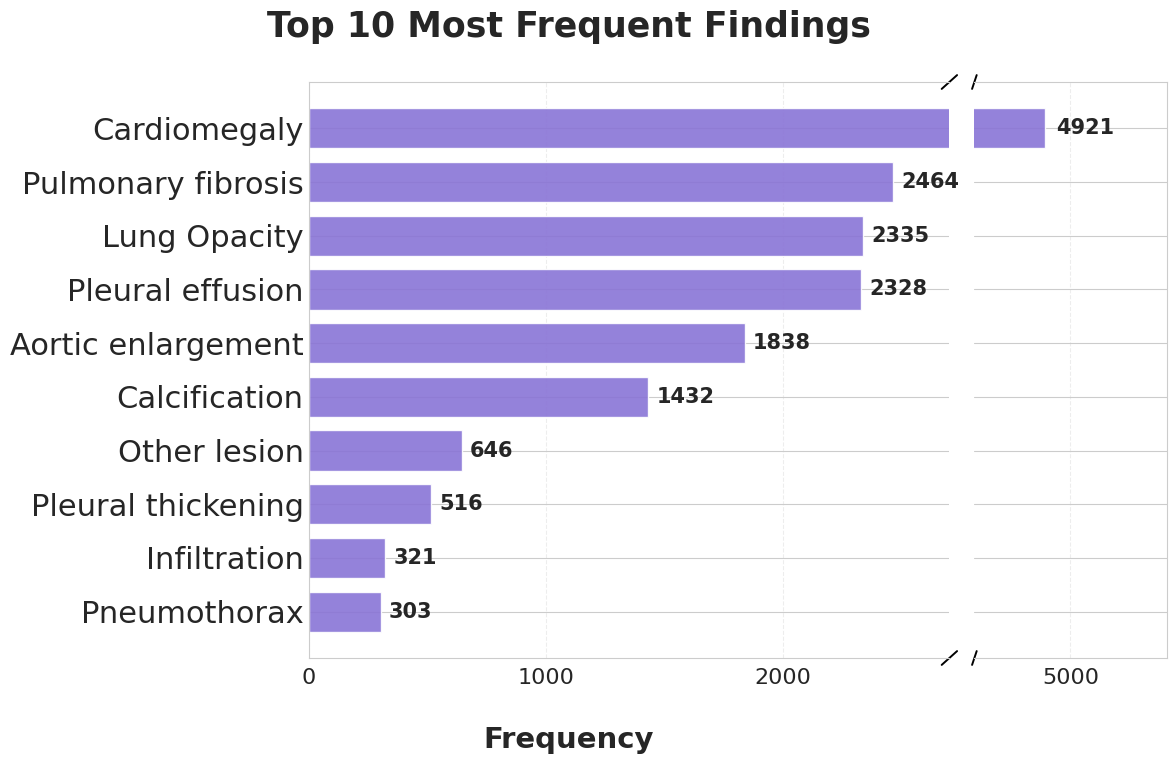

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare the findings
findings = (
    df_vqa['gt_finding']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty or unknown values
findings = findings[
    ~findings.str.lower().isin(
        ['', 'unknown', 'nan', 'none']
    )
]

# Get the 10 most frequent findings
top_findings = (
    findings
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Abbreviate labels that are too long
finding_labels = [
    finding if len(finding) <= 65
    else finding[:62] + '...'
    for finding in top_findings.index
]

positions = np.arange(len(top_findings)) * 0.60

# Create two axes to represent the break
fig, (left_ax, right_ax) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(13, 8),
    gridspec_kw={
        'width_ratios': [4, 1.2],
        'wspace': 0.06
    }
)

# Draw the bars on both axes
for ax in (left_ax, right_ax):
    ax.barh(
        positions,
        top_findings.values,
        color='#8974D6',
        height=0.45,
        alpha=0.9
    )
    ax.set_yticks(positions)
    ax.tick_params(axis='x', labelsize=16)
    ax.grid(axis='x', linestyle='--', alpha=0.35)
    ax.set_axisbelow(True)

# Labels with the original size
left_ax.set_yticklabels(
    finding_labels,
    fontsize=22
)
left_ax.tick_params(axis='y', length=0)
right_ax.tick_params(axis='y', left=False, labelleft=False)

# The axis jumps from 2,700 to 4,700
left_ax.set_xlim(0, 2700)
right_ax.set_xlim(4700, 5300)

left_ax.set_xticks([0, 1000, 2000])
right_ax.set_xticks([5000])

# Hide the inner borders
left_ax.spines['right'].set_visible(False)
right_ax.spines['left'].set_visible(False)

# Draw the diagonal break marks
d = 0.012
break_style = dict(
    color='black',
    clip_on=False,
    linewidth=1.4
)

left_ax.plot(
    (1-d, 1+d), (-d, +d),
    transform=left_ax.transAxes,
    **break_style
)
left_ax.plot(
    (1-d, 1+d), (1-d, 1+d),
    transform=left_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (-d, +d),
    transform=right_ax.transAxes,
    **break_style
)
right_ax.plot(
    (-d, +d), (1-d, 1+d),
    transform=right_ax.transAxes,
    **break_style
)

# Display the frequency at the end of each bar
for position, value in zip(positions, top_findings.values):
    value_ax = left_ax if value <= 2700 else right_ax

    value_ax.text(
        value + 35,
        position,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

fig.suptitle(
    'Top 10 Most Frequent Findings',
    fontsize=25,
    fontweight='bold',
    y=0.97
)

fig.supxlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    y=0.04
)

fig.subplots_adjust(
    left=0.30,
    right=0.96,
    top=0.88,
    bottom=0.16
)

plt.show()

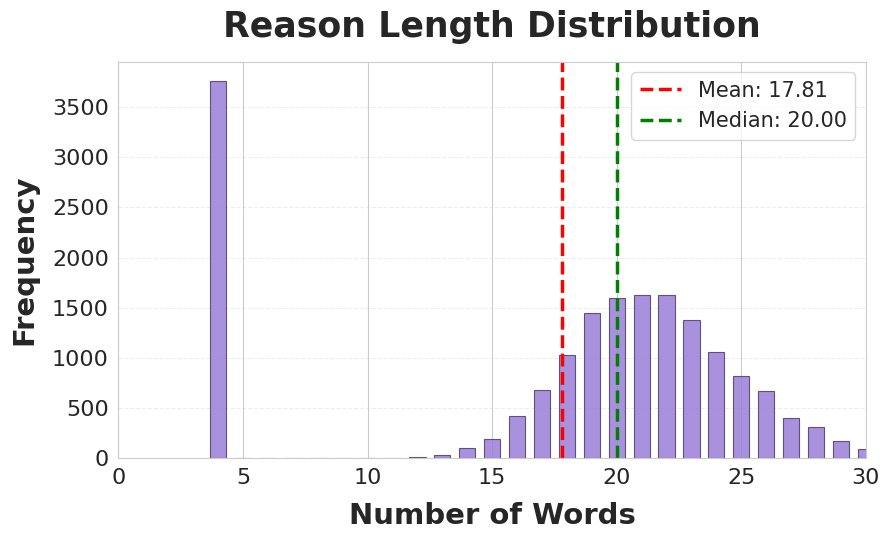

In [15]:
# ============================================================
# FIGURE 9: DISTRIBUTION OF REASON LENGTH
# ViDr-CXR-VQA
# ============================================================

# Get valid lengths
reason_lengths = (
    df_vqa['reason_words']
    .dropna()
    .astype(int)
)

# Remove empty reasons
reason_lengths = reason_lengths[
    reason_lengths > 0
]

# Calculate the mean and median
mean = reason_lengths.mean()
median = reason_lengths.median()

# Calculate the frequency for each number of words
frequencies = (
    reason_lengths
    .value_counts()
    .sort_index()
)

# Include lengths with no records
full_range = range(
    int(reason_lengths.min()),
    int(reason_lengths.max()) + 1
)

frequencies = frequencies.reindex(
    full_range,
    fill_value=0
)

# Create figure
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(
    frequencies.index,
    frequencies.values,
    width=0.65,
    color='#9B7ED9',
    edgecolor='#4B3B70',
    linewidth=0.8,
    alpha=0.85
)

# Mean line
ax.axvline(
    mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {mean:.2f}'
)

# Mean linena
ax.axvline(
    median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median:.2f}'
)

ax.set_title(
    'Reason Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Number of Words',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.tick_params(
    axis='both',
    labelsize=16
)

# Show ticks every 5 words
lower_limit = int(reason_lengths.min())
upper_limit = int(reason_lengths.max())

tick_start = (lower_limit // 5) * 5

ax.set_xticks(
    np.arange(tick_start, upper_limit + 1, 5)
)

ax.set_xlim(
    lower_limit - 0.8,
    upper_limit + 0.8
)


ax.legend(
    fontsize=15,
    loc='upper right',
    frameon=True
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

plt.xlim(0, 30)
plt.tight_layout()
plt.show()

From the preceding chart, each ViDr-CXR-VQA record can include:

question: the question about the X-ray.
answer: the answer.
reason: the explanation justifying that answer.

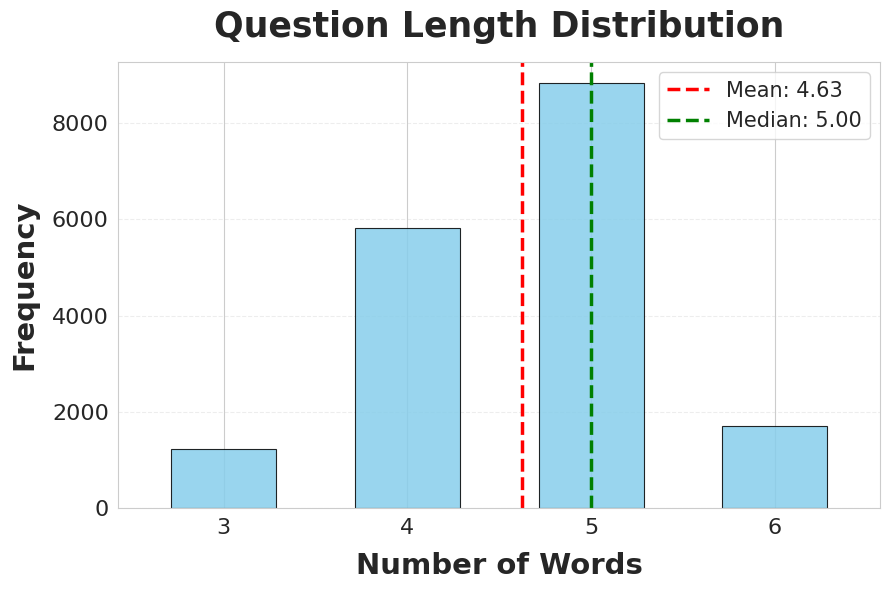

In [16]:
# ============================================================
# FIGURE 10: DISTRIBUTION OF QUESTION LENGTH
# ViDr-CXR-VQA
# ============================================================

# Get valid lengths
question_lengths = (
    df_vqa['question_words']
    .dropna()
    .astype(int)
)

# Remove empty questions
question_lengths = question_lengths[
    question_lengths > 0
]

# Calculate the mean and median
mean = question_lengths.mean()
median = question_lengths.median()

# Calculate frequencies
frequencies = (
    question_lengths
    .value_counts()
    .sort_index()
)

# Closely spaced bar positions
positions = np.arange(len(frequencies)) * 0.35

# Convert the mean and median to plot positions
mean_position = np.interp(
    mean,
    frequencies.index.to_numpy(),
    positions
)

median_position = np.interp(
    median,
    frequencies.index.to_numpy(),
    positions
)

# Create figure compacta
fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    positions,
    frequencies.values,
    width=0.20,
    color='#87CEEB',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85
)

# Mean line
ax.axvline(
    mean_position,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {mean:.2f}'
)

# Mean linena
ax.axvline(
    median_position,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median:.2f}'
)

ax.set_title(
    'Question Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Number of Words',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

# Show the actual number of words on the X-axis
ax.set_xticks(positions)

ax.set_xticklabels(
    frequencies.index,
    fontsize=16
)

ax.tick_params(
    axis='y',
    labelsize=16
)

ax.legend(
    fontsize=15,
    loc='upper right',
    frameon=True
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

ax.margins(x=0.08)

plt.tight_layout()
plt.show()

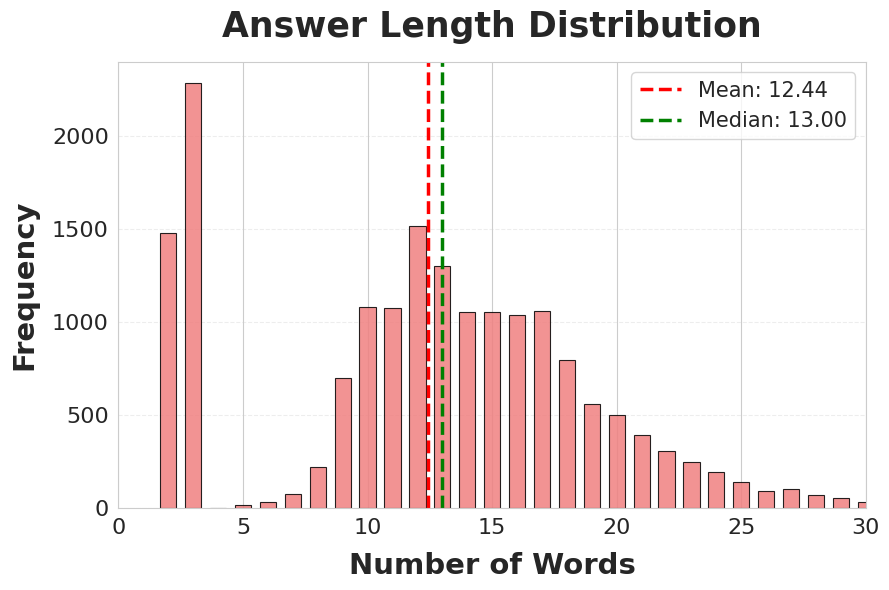

In [17]:
# ============================================================
# FIGURE 11: DISTRIBUTION OF ANSWER LENGTH
# ViDr-CXR-VQA
# ============================================================

# Get valid lengths
answer_lengths = (
    df_vqa['answer_words']
    .dropna()
    .astype(int)
)

# Remove empty answers
answer_lengths = answer_lengths[
    answer_lengths > 0
]

# Calculate the mean and median
mean = answer_lengths.mean()
median = answer_lengths.median()

# Calculate frequencies
frequencies = (
    answer_lengths
    .value_counts()
    .sort_index()
)

# Include lengths with no records
full_range = range(
    int(answer_lengths.min()),
    int(answer_lengths.max()) + 1
)

frequencies = frequencies.reindex(
    full_range,
    fill_value=0
)

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    frequencies.index,
    frequencies.values,
    width=0.65,
    color='#F08080',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85
)

# Mean line
ax.axvline(
    mean,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {mean:.2f}'
)

# Mean linena
ax.axvline(
    median,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median:.2f}'
)

ax.set_title(
    'Answer Length Distribution',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Number of Words',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.tick_params(
    axis='both',
    labelsize=16
)

# Show ticks every five words
lower_limit = int(answer_lengths.min())
upper_limit = int(answer_lengths.max())

tick_start = (lower_limit // 5) * 5

ax.set_xticks(
    np.arange(tick_start, upper_limit + 1, 5)
)

ax.set_xlim(
    lower_limit - 1,
    upper_limit + 1
)

ax.legend(
    fontsize=15,
    loc='upper right',
    frameon=True
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)
plt.xlim(0, 30)
plt.tight_layout()
plt.show()